# Cinque minuti di addestramento, e il modello comincia a scrivere

*Anatomia di un LLM* · capitolo 6, Addestrarlo · script `05-02`, `scripts/05_02_pretrain_agogpt.py`

E' l'unico script lungo del libro. Duemilacinquecento passi su un solo testo --
le ricette dell'Artusi, poco meno di un megabyte -- e alla fine il modello ne
scrive una da solo.
Il checkpoint che produce serve anche ai capitoli seguenti, quindi conviene
lanciarlo e lasciarlo lavorare mentre si legge il resto.

Se lo si interrompe non si perde niente: salva lo stato ogni duecentocinquanta
passi e rilanciandolo riprende da li'.

Si esegue con `python3 scripts/05_02_pretrain_agogpt.py`
e dura circa 5 minuti.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/05_02_pretrain_agogpt.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [1]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [2]:
import argparse
import json
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.data import prepara_split
from llm_anatomy.model import AgoGPT
from llm_anatomy.sample import genera
from llm_anatomy.train import ConfigAddestramento, addestra
from llm_anatomy.utils import (conta_parametri, figura, numero, percorso,
                               prepara, stile_figure, titolo, verifica)

ap = argparse.ArgumentParser()
ap.add_argument("--max-seconds", type=float, default=None,
                help="ferma il segmento dopo N secondi salvando il checkpoint")
ap.add_argument("--passi", type=int, default=2500)
args, _ = ap.parse_known_args()

prepara()

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


device(type='cpu')

In [3]:
titolo("Il modello, e quanto testo gli diamo")
tok, dati_train, dati_val = prepara_split()
cfg = AgoGPTConfig(vocab_size=tok.vocab_size, block_size=128, n_layer=4,
                    d_model=192, n_head=6)
modello = AgoGPT(cfg)
print(f"  {cfg.descrizione()}")
print(f"  parametri:        {numero(conta_parametri(modello))}")
print(f"  di cui embedding: {numero(modello.tok_emb.weight.numel())} "
      f"(condivisi con la testa di uscita)")
print(f"  token di addestramento: {numero(len(dati_train))}")

# lr alto e warmup corto: il modello e' piccolo e il rischio di divergere e'
# basso. Su un modello grande questi numeri sarebbero temerari.
tc = ConfigAddestramento(passi=args.passi, batch_size=16, lr=3e-3, warmup=100,
                         intervallo_eval=100, intervallo_checkpoint=250)
print(f"  passi {tc.passi}, batch {tc.batch_size}, contesto {cfg.block_size}, "
      f"lr {tc.lr}")


Il modello, e quanto testo gli diamo
------------------------------------
  L=4 d=192 h=6/6kv d_head=32 d_ff=512 T=128 norm=rms act=swiglu pos=rope
  parametri:        1.789.056
  di cui embedding: 17.856 (condivisi con la testa di uscita)
  token di addestramento: 789.003
  passi 2500, batch 16, contesto 128, lr 0.003


In [4]:
titolo("Quanto e' ignorante prima di cominciare")
# Un modello che tira a caso fra 93 simboli sbaglia in modo prevedibile: la
# sua perdita vale log(93). Se il modello appena inizializzato si discosta da
# quel numero, qualcosa e' gia' storto prima di cominciare.
perdita_casuale = math.log(tok.vocab_size)
with torch.no_grad():
    x, y = dati_val[:128].unsqueeze(0), dati_val[1:129].unsqueeze(0)
    _, perdita0 = modello(x, y)
print(f"  log(vocab_size) = log({tok.vocab_size}) = {perdita_casuale:.4f}")
print(f"  perdita del modello non addestrato = {perdita0.item():.4f}")
verifica(abs(perdita0.item() - perdita_casuale) < 0.35,
         "il modello inizializzato e' indistinguibile da una scelta uniforme")


Quanto e' ignorante prima di cominciare
---------------------------------------
  log(vocab_size) = log(93) = 4.5326
  perdita del modello non addestrato = 4.4344
  [verifica superata] il modello inizializzato e' indistinguibile da una
                      scelta uniforme


In [5]:
titolo("Duemilacinquecento passi")
esito = addestra(modello, dati_train, dati_val, tc, nome="agogpt",
                 max_seconds=args.max_seconds)
print()
print(f"  passo raggiunto: {esito['passo']}/{tc.passi}")
print(f"  perdita di validazione: {esito['loss_val']:.4f}")
print(f"  durata del segmento: {esito['secondi'] / 60:.1f} min")

if not esito["completato"]:
    print("  segmento non conclusivo: rilanciare lo script per proseguire")
    raise SystemExit(0)

verifica(esito["loss_val"] <= 1.70,
         "la perdita di validazione e' scesa sotto la soglia di 1,70")


Duemilacinquecento passi
------------------------


  passo   100  train 1.983  val 2.048  lr 3.00e-03  104 ms/passo


  passo   200  train 1.709  val 1.840  lr 2.99e-03  104 ms/passo


  passo   300  train 1.566  val 1.768  lr 2.95e-03  104 ms/passo


  passo   400  train 1.384  val 1.670  lr 2.90e-03  104 ms/passo


...

  passo  2100  train 1.015  val 1.286  lr 4.82e-04  104 ms/passo


  passo  2200  train 1.048  val 1.295  lr 4.03e-04  104 ms/passo


  passo  2300  train 1.035  val 1.312  lr 3.46e-04  104 ms/passo


  passo  2400  train 0.875  val 1.283  lr 3.12e-04  104 ms/passo


  passo  2500  train 0.870  val 1.289  lr 3.00e-04  104 ms/passo

  passo raggiunto: 2500/2500
  perdita di validazione: 1.2889
  durata del segmento: 4.3 min
  [verifica superata] la perdita di validazione e' scesa sotto la soglia di
                      1,70


In [6]:
titolo("Come scende la perdita")
righe = [json.loads(r) for r in
         percorso("outputs", "agogpt_log.jsonl").read_text().splitlines()]
righe = righe[-(tc.passi // tc.intervallo_eval):]
print(f"  {'passo':>6} {'train':>8} {'val':>8} {'ms/passo':>10}")
for r in righe[::5]:
    print(f"  {r['passo']:6d} {r['loss_train']:8.3f} {r['loss_val']:8.3f} "
          f"{r['ms_per_passo']:10.0f}")
ultimo = righe[-1]
print(f"  {ultimo['passo']:6d} {ultimo['loss_train']:8.3f} "
      f"{ultimo['loss_val']:8.3f} {ultimo['ms_per_passo']:10.0f}")
print()
print(f"  perplexity finale: {math.exp(ultimo['loss_val']):.2f} "
      f"su {tok.vocab_size} simboli")


Come scende la perdita
----------------------
   passo    train      val   ms/passo
     100    1.983    2.048        104
     600    1.345    1.534        104
    1100    1.249    1.450        104
    1600    0.976    1.391        104
    2100    1.015    1.286        104
    2500    0.870    1.289        104

  perplexity finale: 3.63 su 93 simboli



Le stesse cose, disegnate
-------------------------


  [figura] outputs/figures/05-02_curva_pretrain.pdf


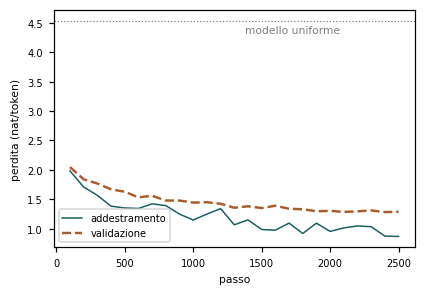

In [7]:
titolo("Le stesse cose, disegnate")
fig, ax = plt.subplots(figsize=(stile_figure(), 2.8))
ax.plot([r["passo"] for r in righe], [r["loss_train"] for r in righe],
        label="addestramento", lw=1)
ax.plot([r["passo"] for r in righe], [r["loss_val"] for r in righe],
        label="validazione", lw=1.6)
ax.axhline(math.log(tok.vocab_size), ls=":", lw=0.8, color="gray")
ax.text(tc.passi * 0.55, math.log(tok.vocab_size) - 0.08,
        "modello uniforme", color="gray", va="top")
ax.set_xlabel("passo")
ax.set_ylabel("perdita (nat/token)")
ax.legend()
figura(fig, "05-02_curva_pretrain")

In [8]:
titolo("Che cosa scrive")
# temperatura 0,8: un po' sotto uno, quindi il modello e' leggermente piu'
# prudente di quanto la sua distribuzione suggerisca. A uno divaga, a 0,5
# ripete.
gen = torch.Generator().manual_seed(1337)
avvio = torch.tensor([tok.encode("800. Risotto")], dtype=torch.long)
uscita = genera(modello, avvio, n_token=400, temp=0.8, k=0, generatore=gen)
testo = tok.decode(uscita[0])
print(f"  avvio: {'800. Risotto'!r}, temperatura 0,8, 400 token")
print()
for riga in testo.split("\n"):
    print(f"  | {riga[:74]}")

parole = [p for p in testo.replace("\n", " ").split(" ") if p.isalpha()]
print()
print(f"  parole alfabetiche generate: {len(parole)}")
media = sum(len(p) for p in parole) / max(1, len(parole))
print(f"  lunghezza media: {media:.1f}")


Che cosa scrive
---------------


  avvio: '800. Risotto', temperatura 0,8, 400 token

  | 800. Risotto grasso e magro, quando è e
  | conditelo a bollire ancora qualche cucchiaino di manzo giorniti.
  | 
  | 349. Torline a grande, distendetelo sulla spianatoia e gettatelo dai
  | preferini, o meno non occorre ridotto non potrà un poco di sale e sopra
  | qualche minuto e la farina e la amico dopo setterete può bastare con
  | burro e spolverizzata di carota.
  | 
  | Avvitlate la pappa renderla poco meno che i fogli di prezzemol

  parole alfabetiche generate: 63
  lunghezza media: 4.7


## Da provare

riduci i passi a 500 e guarda che testo esce.